# Soloving 1D Schrodinger equation for a particle in a box ( i.e V = 0), by matrix method

# $\frac{d^2 \psi}{dx^2} = -\frac{2m}{\hbar^2}E\psi$

In [209]:
import numpy as np
import scipy.constants as sc
from matplotlib import pyplot as plt
import numpy.linalg as lin
import ipywidgets as widgets
from ipywidgets import interact

In [185]:
L  = 100
t = 1
H = np.zeros((L,L))

In [186]:
for i in range(0,L):
    H[i,i]= 2*t
    if (i <L-1 ):
        
        H[i][i+1]=-t
        
    if (i >=1):
        H[i][i-1]= -t

In [187]:
H

array([[ 2., -1.,  0., ...,  0.,  0.,  0.],
       [-1.,  2., -1., ...,  0.,  0.,  0.],
       [ 0., -1.,  2., ...,  0.,  0.,  0.],
       ...,
       [ 0.,  0.,  0., ...,  2., -1.,  0.],
       [ 0.,  0.,  0., ..., -1.,  2., -1.],
       [ 0.,  0.,  0., ...,  0., -1.,  2.]])

In [188]:
e,v = lin.eigh(H)

In [191]:
e.shape

(100,)

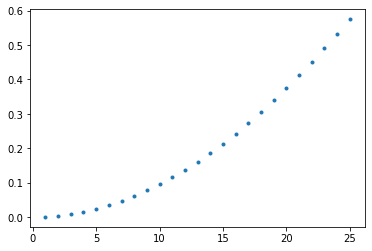

In [193]:
N =100
ind = np.arange(1,N+1,1)  # we prepare a table with integers from 1 to N
#print(ind)
# we plot the numerical energy levels (the first 50 energy levels)
plt.plot(ind[:25], e[:25],'.')

# Ground state plot

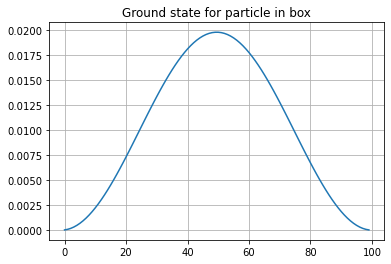

In [211]:
nn=1
plt.plot(np.abs(v[::,nn-1])**2)
plt.title("Ground state for particle in box")
plt.grid()
plt.show()

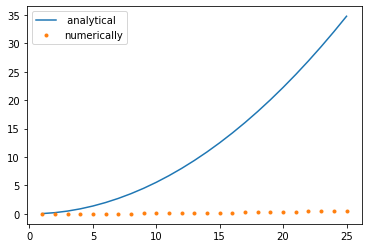

In [201]:
def energy(n):
    L = (26)*1e-10
    ret = (((n*np.pi*sc.hbar)**2)/(2*sc.m_e*L**2))/sc.eV
    return  ret
n = np.arange(1,25+1,1)
energy_analytical= energy(n)
plt.plot(n, energy_analytical, label = " analytical")
plt.plot(ind[:25], e[:25],'.', label =  "numerically") 
plt.legend()

In [146]:
e[:1]

array([0.00096744])

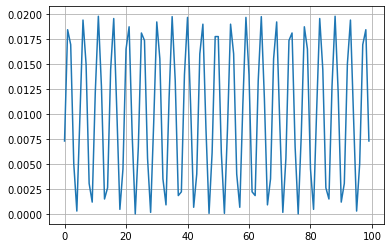

In [147]:
plt.plot(np.abs(v[::,20])**2)
plt.grid()
plt.show()

# H atom problem, $ -\frac{\hbar^2}{2m} \frac{d^2 u}{dr^2} + [-\frac{e^2}{4\pi \epsilon_{0}} \frac{1}{r} + \frac{\hbar^2}{2m} \frac{l(l+1)}{r^2}]u = Eu$

In [172]:
import numpy as np 
from scipy import constants as const
from scipy import sparse 
from scipy.sparse.linalg import eigs
from matplotlib import pyplot as plt

In [176]:
hbar = const.hbar
e = const.e 
m_e = const.m_e 
pi = const.pi 
epsilon_0 = const.epsilon_0
l = 0  # here l = 0, i.e s wave

n = 1000
r , h = np.linspace ( 1.0*1e-9 , 0.0 , n , endpoint = False , retstep = True ) 
coefl = -hbar**2/(2*m_e*h**2)
coef2 = lambda r: - e**2/(4.0*pi*epsilon_0*r) + hbar**2/(2*m_e)*l*(1+1)/r**2
D = - 2*np.ones(n)
D_off = np.ones(n - 1)
M1 = coefl*sparse.diags([D, D_off, D_off], (0, -1, 1))
M2 = coef2(r)*np.diag(np.ones(n))

H = M1 + M2
n_eig = 20
eig_val, eig_vec = eigs(H, k = n_eig, which = 'SM')
indx = np.argsort(eig_val)
eig_val = eig_val[indx]
eig_vec = eig_vec[:,indx]
v= eig_vec.T
P = [np.abs(v[i]**2) for i in range(n_eig)]

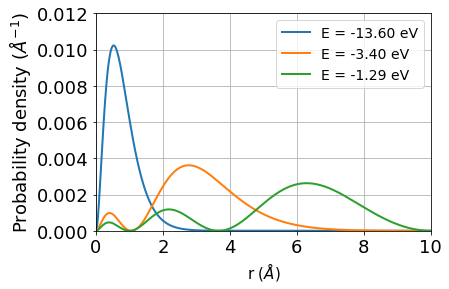

In [177]:
plt.figure() 
r = r*1e+10 
engy = ['E = {:5.2f} eV'.format(eig_val[i].real/e) for i in range (3)] 
plt.plot(r, P[0], lw = 2, label = engy[0]) 
plt.plot(r, P[1], lw = 2, label = engy[1])
plt.plot(r, P[2], lw = 2, label = engy[2]) 
plt.legend(fontsize = 14) 
plt.xlabel('r ($\AA$)', size = 15)
plt.ylabel('Probability density (${\AA}^{-1}$)', size = 18)
plt.xticks(fontsize = 18) 
plt.yticks(fontsize = 18) 
plt.xlim(0, 10) 
plt.ylim(0, 0.012)
plt.grid()
plt.savefig('H_atom.pdf')
plt.show() 

# Definite intergral

# $\int_{0}^2 x^3 dx$

In [151]:
from scipy.integrate import quad
f = lambda x:x**3
quad(f, 0 ,2)

(4.0, 4.440892098500626e-14)

# Same intergration using Simpson method 

In [152]:
from scipy.integrate import simps
f = lambda x:x**3
x = np.linspace(0,2,1000)
simps(f(x),x)

4.0000000040120245

# Improper integral, $\int_{-\infty}^\infty \frac{1}{\sigma \sqrt{2\pi}} \exp(\frac{-(x-\mu)^2}{2\sigma^2})$

In [153]:
 mu, sigma = 0.5, 1.0
f = lambda x:1/(sigma*np.sqrt(2*np.pi))*np.exp(-(x-mu)**2/(2*sigma**2))
quad(f, -np.inf, np.inf)

(1.0000000000000002, 8.47954090895265e-10)

# Double integral $\int_{0}^\infty \int_{1}^\infty  t^n\exp(-xt) dx dt$

# By using quad

In [154]:
n =2
def f(t,x):
    return np.exp(-x*t)/(t**n)
def F(x):
    return quad(f, 1, np.inf, args = (x, ))[0]
print(quad(F,0, np.inf))

(0.4999999999985751, 1.8855521033422917e-09)


# By using dblquad

In [155]:
from scipy.integrate import dblquad
f = lambda t, x: np.exp(-x*t)/(t**n)
dblquad(f, 0, np.inf, 1, np.inf)

(0.4999999999985751, 1.3894083651858995e-08)

# Solving ordinary differential equations , $\frac{dx}{dt} = -kx$ 

In [156]:
from scipy.integrate import odeint    # for integration

In [157]:
k = 1
def f(x,t):
    dxdt= -k*x
    return dxdt

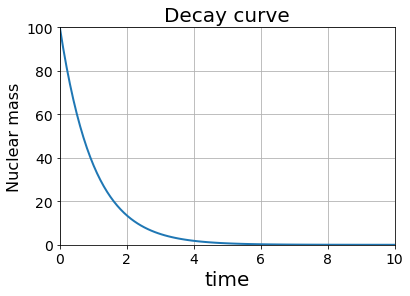

In [170]:
t = np.linspace(0,10,100)
x0 = 100                        #intial value
# solution module
sol = odeint(f, x0, t)
plt.plot(t, sol, lw =2)
plt.axis([0,10, 0, 100])
plt.title('Decay curve', fontsize = 20)
plt.xlabel('time', fontsize = 20)
plt.xticks(fontsize = 14)
plt.ylabel("Nuclear mass", fontsize=16)
plt.yticks(fontsize=14)
plt.savefig('decay.pdf')
plt.grid()
plt.show()

# Solving second order ODE, $\frac{d^2{x}}{d{t^2}} + \lambda \frac{dx}{dt} + k.x = 0$

# Damped Harmonic motion

In [159]:
k, lam = 1.0, 0.2

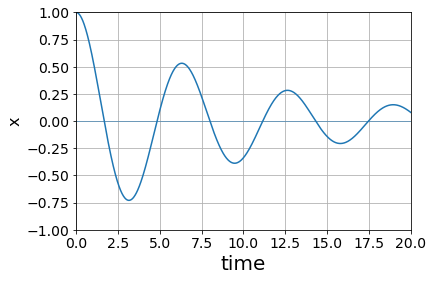

In [160]:
def shm(u,t):
    x = u[0]
    y = u[1]
    dxdt = y
    dydt = -k*x - lam*y
    return np.array([dxdt, dydt])
u0 = [1, 0]
t = np.linspace(0,20, 1000)
sol = odeint(shm, u0, t)
x = sol[:,0]
y = sol[:,1]
plt.plot(t, x)
plt.axis([0,20, -1, 1])
plt.axhline(lw = 0.5)
plt.xlabel('time', fontsize = 20)
plt.xticks(fontsize = 14)
plt.ylabel("x", fontsize=16)
plt.yticks(fontsize=14)
plt.grid()
plt.show()

#  Diffusion in 1D, $\frac{\partial u}{\partial t} = \frac{\partial^2 u}{\partial x^2}$

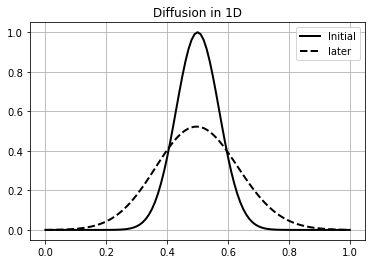

In [161]:
x = np.arange(0,1.01,0.01)
u = np.exp(-(x-0.5)**2/0.01) # Initial distribution
plt.plot(x, u, '-', label = 'Initial', c  = 'k', lw =2)

for t in range(200):
    for i in range(1,100):
        u[i] += 0.25*(u[i+1]-2*u[i]+u[i-1])
        
plt.plot(x, u, '--', label = "later", c = 'k', lw =2)
plt.title("Diffusion in 1D")
plt.legend()
plt.grid()
plt.show()

# Diffusion in 2D, $\frac{\partial u}{\partial t} = \frac{\partial^2 u}{\partial x^2} + \frac{\partial^2 u}{\partial y^2}$

In [162]:
u = np.zeros((101, 101))
u[50,50] = 1
for t in range(200):
    for i in range(1, 100):
        for j in range(1, 100):
            u[i, j] += (u[i+1, j] + u[i-1, j] + u[i, j+1] + u[i, j-1] - 4*u[i,j])/4

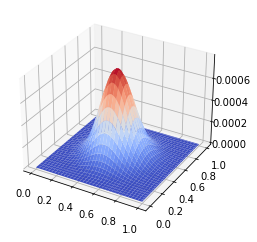

In [163]:
import matplotlib.pyplot as plt
from matplotlib import cm
from mpl_toolkits import mplot3d
x = np.linspace(0, 1,  101)
y = np.linspace(0, 1,  101)
X, Y = np.meshgrid(x, y)
fig  = plt.figure()
ax = plt.axes(projection = "3d")
ax.plot_surface(X, Y, u, cmap= cm.coolwarm)
plt.show()

# A system consist of two particles each of which can be in any single particles level of respective energies 0 and $\epsilon$. The system is in contact with heat reservoir at temperature T. The particle follow MB-statistics. Find
(i) Partion function (ii) Average energy (iii) Relative R.M.S fluctuation (iv) Specific heat capacity at constant volume

# Partion function w.r.t $\epsilon$, $Z = 1 + \exp(-\frac{2\epsilon}{KT}) + 2\exp(-\frac{\epsilon}{KT})$ 

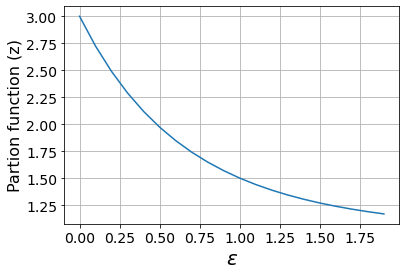

In [164]:
KT =1
eps = np.arange(0,2, 0.1)
Z = 1 + np.exp(-2*eps) + np.exp(-eps)
plt.plot(eps, Z)
plt.xlabel('$\epsilon$', fontsize = 20)
plt.xticks(fontsize = 14)
plt.ylabel("Partion function (z)", fontsize=16)
plt.yticks(fontsize=14)
plt.grid()
plt.show()

# Average energy, $E_{avg} = \frac {\sum_{i} g_{i} \epsilon_{i} \exp(-\frac{\epsilon_{i}}{KT})}{Z}$

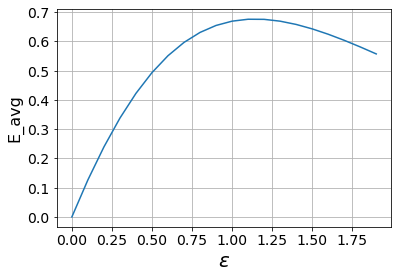

In [165]:
E_avg = ((2*eps)*(np.exp(-2*eps) + np.exp(-eps)))/Z
plt.plot(eps, E_avg)
plt.xlabel('$\epsilon$', fontsize = 20)
plt.xticks(fontsize = 14)
plt.ylabel("E_avg", fontsize=16)
plt.yticks(fontsize=14)
plt.grid()
plt.show()

In [166]:
E_square_avg = ((2*eps**2)/Z)*(2*np.exp(-2*eps)+np.exp(-eps))

/tmp/ipykernel_24209/1116701236.py:1: RuntimeWarning: invalid value encountered in true_divide
  E_rel_fluctuation = np.sqrt(E_square_avg)/E_avg


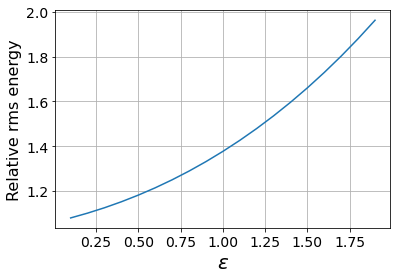

In [167]:
E_rel_fluctuation = np.sqrt(E_square_avg)/E_avg
plt.plot(eps, E_rel_fluctuation)
plt.xlabel('$\epsilon$', fontsize = 20)
plt.xticks(fontsize = 14)
plt.ylabel("Relative rms energy", fontsize=16)
plt.yticks(fontsize=14)
plt.grid()
plt.show()

# Specific heat calculation, $C_{V} = \frac{\partial <E>}{\partial T}$

In [168]:
K = 1
eps = 1
T = np.linspace(0.1, 2, 100)
Z_T = 1 + np.exp(-2*eps/T) + 2*np.exp(-eps/T)
E_T = ((2*eps)/Z_T)*(np.exp(-2*eps/T) + np.exp(-eps/T))
E_square_avg_T =  ((2*eps**2)/Z_T)*(2*np.exp(-2*eps/T) + np.exp(-eps/T))
C_v = (E_square_avg_T - (E_T)**2)/T**2

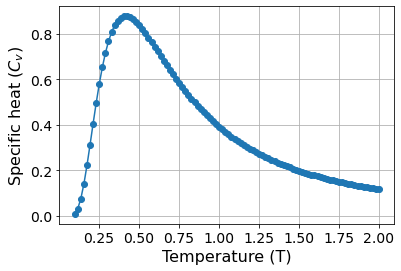

In [169]:
plt.plot(T, C_v, "o-")
plt.xlabel('Temperature (T)', fontsize = 16)
plt.xticks(fontsize = 14)
plt.ylabel("Specific heat ($C_{v}$)", fontsize=16)
plt.yticks(fontsize=14)
plt.grid()
plt.show()